# Generating Novel Music Compositions with an Open-Source Audio LLM (MusicGen)
### A Complete Project



In [ ]:
# Check GPU availability
!nvidia-smi --query-gpu=name,memory.total --format=csv


name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
# Install core libraries
!pip install -q -U "transformers>=4.31.0" datasets soundfile librosa accelerate peft

# Clone and install the LoRA fine-tuning toolkit for MusicGen
!git clone -q https://github.com/ylacombe/musicgen-dreamboothing.git
%cd musicgen-dreamboothing
!pip install -q -e .
%cd ..


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 17.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 25.0.1 which is incompatible.
/content/musicgen-dreamboothing
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.9 MB/s eta 0:00:00
/content


In [ ]:
# Non-interactive accelerate config: single GPU, fp16
!accelerate config default


accelerate configuration saved at /root/.cache/huggingface/accelerate/default_config.yaml


In [ ]:
# Log in to Hugging Face Hub (needed to download MusicGen and to push our prepared dataset).
# This opens a widget where you paste a token created at https://huggingface.co/settings/tokens
# (make sure the token has "write" access).
from huggingface_hub import notebook_login
notebook_login()


In [ ]:
import os
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset, Audio
from IPython.display import Audio as IPyAudio, display

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [ ]:
raw_dataset = load_dataset("lewtun/music_genres_small", split="train")
print(raw_dataset)
print("\nGenres present:", sorted(set(raw_dataset["genre"])))


README.md:   0%|          | 0.00/487 [00:00<?, ?B/s]

data/train-00000-of-00001-63d68663287b16(…): reconstructing file:   0%|          |  0.00B /  391MB            

data/train-00000-of-00001-63d68663287b16(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dataset({
    features: ['audio', 'song_id', 'genre_id', 'genre'],
    num_rows: 1000
})

Genres present: ['Chiptune / Glitch', 'Electronic', 'Experimental', 'Folk', 'Hip-Hop', 'Instrumental', 'International', 'Pop', 'Punk', 'Rock']


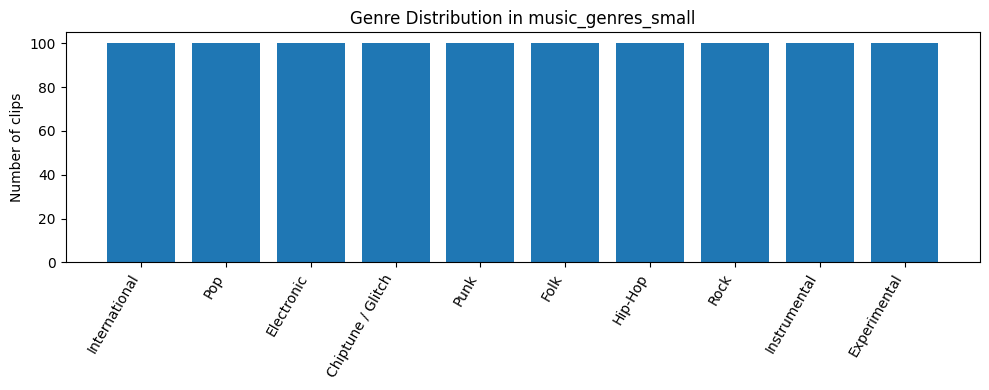

In [ ]:
# Inspect the genre distribution
genre_counts = {}
for g in raw_dataset["genre"]:
    genre_counts[g] = genre_counts.get(g, 0) + 1

plt.figure(figsize=(10, 4))
plt.bar(genre_counts.keys(), genre_counts.values())
plt.xticks(rotation=60, ha="right")
plt.title("Genre Distribution in music_genres_small")
plt.ylabel("Number of clips")
plt.tight_layout()
plt.show()


In [ ]:
# Listen to one sample clip
sample = raw_dataset[1]
print("Genre:", sample["genre"])
print("Sampling rate:", sample["audio"]["sampling_rate"])
display(IPyAudio(sample["audio"]["array"], rate=sample["audio"]["sampling_rate"]))


Genre: International
Sampling rate: 44100


In [ ]:
MAX_EXAMPLES = 300    # subset size for a manageable Colab fine-tuning run; set to None for all 1000
MIN_DURATION = 1.0
MAX_DURATION = 30.0

def make_caption(example):
    genre = example["genre"].replace("/", " ").replace("-", " ").lower()
    example["description"] = f"a {genre} music track"
    return example

def get_duration(example):
    example["duration"] = len(example["audio"]["array"]) / example["audio"]["sampling_rate"]
    return example

dataset = raw_dataset.map(make_caption)
dataset = dataset.map(get_duration)
dataset = dataset.filter(lambda ex: MIN_DURATION <= ex["duration"] <= MAX_DURATION)

if MAX_EXAMPLES is not None:
    dataset = dataset.shuffle(seed=seed).select(range(min(MAX_EXAMPLES, len(dataset))))

print(f"Dataset size after filtering/subsetting: {len(dataset)}")
print("Example caption:", dataset[0]["description"])


Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dataset size after filtering/subsetting: 300
Example caption: a experimental music track


In [ ]:
# Train / test split
split_dataset = dataset.train_test_split(test_size=0.1, seed=seed)
print(split_dataset)


DatasetDict({
    train: Dataset({
        features: ['audio', 'song_id', 'genre_id', 'genre', 'description', 'duration'],
        num_rows: 270
    })
    test: Dataset({
        features: ['audio', 'song_id', 'genre_id', 'genre', 'description', 'duration'],
        num_rows: 30
    })
})


In [ ]:
# ---- Push the prepared, captioned dataset to YOUR Hugging Face Hub namespace ----
# The training script (Step 5) reads the dataset FROM the Hub, so this step is required.
from huggingface_hub import whoami

hf_username = whoami()["name"]
dataset_repo_id = f"{hf_username}/music-genres-captioned-small"

split_dataset.push_to_hub(dataset_repo_id, private=True)
print(f"Pushed dataset to: https://huggingface.co/datasets/{dataset_repo_id}")


Setting num_proc from 1 back to 1 for the train split to disable multiprocessing as it only contains one shard.


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/270 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/2 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

...

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmpw3cltb48.parquet    :  43%|####2     | 5.08MB / 11.9MB            

Validating                    :           |   0%            

Pushed dataset to: https://huggingface.co/datasets/sachintakmare/music-genres-captioned-small


In [ ]:
from transformers import AutoProcessor, MusicgenForConditionalGeneration

MODEL_ID = "facebook/musicgen-small"

processor = AutoProcessor.from_pretrained(MODEL_ID)
demo_model = MusicgenForConditionalGeneration.from_pretrained(MODEL_ID).to(device)

sample = split_dataset["train"][0]
audio_array = sample["audio"]["array"]
sr = sample["audio"]["sampling_rate"]
text = sample["description"]

print("Caption:", text)
print("Raw audio shape:", audio_array.shape, "at", sr, "Hz")

# 1) Text -> token ids (via the frozen T5 tokenizer)
text_inputs = processor(text=[text], padding=True, return_tensors="pt").to(device)
print("\nText input_ids shape:", text_inputs["input_ids"].shape)

# 2) Audio -> discrete codes (via the frozen EnCodec audio encoder)
audio_inputs = processor(audio=[audio_array], sampling_rate=sr, return_tensors="pt").to(device)
with torch.no_grad():
    encoded = demo_model.audio_encoder.encode(
        audio_inputs["input_values"], audio_inputs.get("padding_mask", None)
    )
audio_codes = encoded.audio_codes  # shape: (batch, 1, num_codebooks, seq_len)
print("Encoded audio token shape (batch, 1, codebooks, timesteps):", audio_codes.shape)
print("This is the discrete 'vocabulary' sequence the Transformer decoder learns to predict —")
print("exactly analogous to word-token ids in a text LLM.")


Loading weights:   0%|          | 0/611 [00:00<?, ?it/s]

Caption: a rock music track
Raw audio shape: (1321967,) at 44100 Hz

Text input_ids shape: torch.Size([1, 6])


ValueError: The model corresponding to this feature extractor: EncodecFeatureExtractor {
  "chunk_length_s": null,
  "feature_extractor_type": "EncodecFeatureExtractor",
  "feature_size": 1,
  "overlap": null,
  "padding_side": "left",
  "padding_value": 0.0,
  "return_attention_mask": true,
  "sampling_rate": 32000
}
 was trained using a sampling rate of 32000. Please make sure that the provided audio input was sampled with 32000 and not 44100.

In [ ]:
def count_params(module):
    return sum(p.numel() for p in module.parameters())

print(f"Text encoder params:        {count_params(demo_model.text_encoder):>12,}")
print(f"Audio encoder/decoder (EnCodec) params: {count_params(demo_model.audio_encoder):>12,}")
print(f"Decoder (the Transformer LM) params:    {count_params(demo_model.decoder):>12,}")
print(f"Total model params:         {count_params(demo_model):>12,}")


Text encoder params:         109,628,544
Audio encoder/decoder (EnCodec) params:   56,884,674
Decoder (the Transformer LM) params:     419,584,000
Total model params:          586,884,674


In [ ]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=16,                       # rank of the low-rank update matrices
    lora_alpha=32,               # scaling factor
    target_modules=["q_proj", "v_proj"],  # attach LoRA to the attention query/value projections
    lora_dropout=0.05,
    bias="none",
)

# Demonstration only (the actual training run in Step 5 applies LoRA internally via --use_lora).
lora_demo_model = get_peft_model(demo_model.decoder, lora_config)
lora_demo_model.print_trainable_parameters()


ImportError: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported

In [ ]:
OUTPUT_DIR = "./musicgen-small-lora-genres"

training_args = [
    "--use_lora",
    "--model_name_or_path", "facebook/musicgen-small",
    "--dataset_name", dataset_repo_id,
    "--target_audio_column_name", "audio",
    "--text_column_name", "description",
    "--train_split_name", "train",
    "--eval_split_name", "test",
    "--output_dir", OUTPUT_DIR,
    "--do_train",
    "--fp16",
    "--num_train_epochs", "3",
    "--gradient_accumulation_steps", "8",
    "--gradient_checkpointing",
    "--per_device_train_batch_size", "2",
    "--learning_rate", "2e-4",
    "--adam_beta1", "0.9",
    "--adam_beta2", "0.99",
    "--weight_decay", "0.1",
    "--guidance_scale", "1.0",
    "--do_eval",
    "--predict_with_generate",
    "--include_inputs_for_metrics",
    "--eval_steps", "25",
    "--evaluation_strategy", "steps",
    "--per_device_eval_batch_size", "1",
    "--max_eval_samples", "8",
    "--generation_max_length", "250",
    "--dataloader_num_workers", "4",
    "--logging_steps", "5",
    "--max_duration_in_seconds", "30",
    "--min_duration_in_seconds", "1.0",
    "--preprocessing_num_workers", "4",
    "--pad_token_id", "2048",
    "--decoder_start_token_id", "2048",
    "--seed", "456",
    "--overwrite_output_dir",
]

print("Training command assembled. Arguments:")
print(" ".join(training_args))


Training command assembled. Arguments:
--use_lora --model_name_or_path facebook/musicgen-small --dataset_name sachintakmare/music-genres-captioned-small --target_audio_column_name audio --text_column_name description --train_split_name train --eval_split_name test --output_dir ./musicgen-small-lora-genres --do_train --fp16 --num_train_epochs 3 --gradient_accumulation_steps 8 --gradient_checkpointing --per_device_train_batch_size 2 --learning_rate 2e-4 --adam_beta1 0.9 --adam_beta2 0.99 --weight_decay 0.1 --guidance_scale 1.0 --do_eval --predict_with_generate --include_inputs_for_metrics --eval_steps 25 --evaluation_strategy steps --per_device_eval_batch_size 1 --max_eval_samples 8 --generation_max_length 250 --dataloader_num_workers 4 --logging_steps 5 --max_duration_in_seconds 30 --min_duration_in_seconds 1.0 --preprocessing_num_workers 4 --pad_token_id 2048 --decoder_start_token_id 2048 --seed 456 --overwrite_output_dir


In [ ]:
import subprocess

cmd = ["python", "musicgen-dreamboothing/dreambooth_musicgen.py"] + training_args
print("Running:\n", " ".join(cmd))

process = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
for line in process.stdout:
    print(line, end="")
process.wait()
print("\nTraining finished with return code:", process.returncode)


Running:
 python musicgen-dreamboothing/dreambooth_musicgen.py --use_lora --model_name_or_path facebook/musicgen-small --dataset_name sachintakmare/music-genres-captioned-small --target_audio_column_name audio --text_column_name description --train_split_name train --eval_split_name test --output_dir ./musicgen-small-lora-genres --do_train --fp16 --num_train_epochs 3 --gradient_accumulation_steps 8 --gradient_checkpointing --per_device_train_batch_size 2 --learning_rate 2e-4 --adam_beta1 0.9 --adam_beta2 0.99 --weight_decay 0.1 --guidance_scale 1.0 --do_eval --predict_with_generate --include_inputs_for_metrics --eval_steps 25 --evaluation_strategy steps --per_device_eval_batch_size 1 --max_eval_samples 8 --generation_max_length 250 --dataloader_num_workers 4 --logging_steps 5 --max_duration_in_seconds 30 --min_duration_in_seconds 1.0 --preprocessing_num_workers 4 --pad_token_id 2048 --decoder_start_token_id 2048 --seed 456 --overwrite_output_dir
Traceback (most recent call last):
  Fil

## Step 6: Generate Novel Music Compositions

We load the fine-tuned LoRA adapters on top of the frozen base model (exactly as shown in the
`musicgen-dreamboothing` README) and generate new clips from text prompts — including genres the
model saw during fine-tuning, so you can judge how well it learned.


In [ ]:
import soundfile as sf
from peft import PeftModel

base_model = MusicgenForConditionalGeneration.from_pretrained(
    "facebook/musicgen-small", torch_dtype=torch.float16
).to(device)

finetuned_model = PeftModel.from_pretrained(base_model, OUTPUT_DIR).to(device)
finetuned_processor = AutoProcessor.from_pretrained(OUTPUT_DIR)

sampling_rate = finetuned_model.config.audio_encoder.sampling_rate
print("Output sampling rate:", sampling_rate)


Loading weights:   0%|          | 0/611 [00:00<?, ?it/s]

ValueError: Can't find 'adapter_config.json' at './musicgen-small-lora-genres'

In [ ]:
prompts = [
    "an electronic music track",
    "a jazz music track",
    "a classical music track",
    "a hip-hop music track",
]

inputs = finetuned_processor(text=prompts, padding=True, return_tensors="pt").to(device)

with torch.no_grad():
    audio_values = finetuned_model.generate(
        **inputs, do_sample=True, guidance_scale=3.0, max_new_tokens=512
    )

audio_values = audio_values.cpu().float().numpy()

os.makedirs("generated_music", exist_ok=True)
for i, (prompt, audio) in enumerate(zip(prompts, audio_values)):
    path = f"generated_music/sample_{i}_{prompt.replace(' ', '_')}.wav"
    sf.write(path, audio.T, sampling_rate)
    print(f"Saved: {path}")
    display(IPyAudio(audio, rate=sampling_rate))


NameError: name 'finetuned_processor' is not defined

In [ ]:
# ---- Before vs. after comparison: same prompt, base model vs. fine-tuned model ----
compare_prompt = ["a jazz music track"]

base_inputs = processor(text=compare_prompt, padding=True, return_tensors="pt").to(device)
with torch.no_grad():
    base_audio = demo_model.generate(**base_inputs, do_sample=True, guidance_scale=3.0, max_new_tokens=512)
base_audio = base_audio.cpu().float().numpy()[0]

ft_inputs = finetuned_processor(text=compare_prompt, padding=True, return_tensors="pt").to(device)
with torch.no_grad():
    ft_audio = finetuned_model.generate(**ft_inputs, do_sample=True, guidance_scale=3.0, max_new_tokens=512)
ft_audio = ft_audio.cpu().float().numpy()[0]

print("BASE (pretrained, not fine-tuned) MusicGen, prompt:", compare_prompt[0])
display(IPyAudio(base_audio, rate=sampling_rate))

print("\nFINE-TUNED (LoRA, on our genre dataset) MusicGen, prompt:", compare_prompt[0])
display(IPyAudio(ft_audio, rate=sampling_rate))


NameError: name 'finetuned_processor' is not defined

In [ ]:
# ---- Save the fine-tuned LoRA adapters for later reuse / deployment ----
finetuned_model.save_pretrained("final_lora_adapters")
finetuned_processor.save_pretrained("final_lora_adapters")

!zip -rq final_lora_adapters.zip final_lora_adapters
print("Saved and zipped LoRA adapters to final_lora_adapters.zip")

from google.colab import files
files.download("final_lora_adapters.zip")
